<a href="https://colab.research.google.com/github/adnannurrohman8/Project-PSD-Kelompok-J/blob/anggota2-feature%26algo1/NOTEBOOK/Feature%20Engineering%20%26%20Algoritma%201.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Penelaahan Data**

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("ruchikakumbhar/placement-prediction-dataset")

print("Path to dataset files:", path)
data = pd.read_csv(os.path.join(path, "placementdata.csv"))
data.head()
#menampilkan dimensi dataset
data.shape

data.info()
#Mengidentifikasi variabel numerik dan kategorik
numerik = data.select_dtypes(include=['int64', 'float64'])
numerik = numerik.drop(columns=['StudentID'])
kategorik = data.select_dtypes(include=['object'])

print("Variabel Numerik:")
print(numerik.columns.tolist())

print("\nVariabel Kategorik:")
print(kategorik.columns.tolist())

print("\nVariabel Identitas:")
print(['StudentID'])

Using Colab cache for faster access to the 'placement-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/placement-prediction-dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   StudentID                  10000 non-null  int64  
 1   CGPA                       10000 non-null  float64
 2   Internships                10000 non-null  int64  
 3   Projects                   10000 non-null  int64  
 4   Workshops/Certifications   10000 non-null  int64  
 5   AptitudeTestScore          10000 non-null  int64  
 6   SoftSkillsRating           10000 non-null  float64
 7   ExtracurricularActivities  10000 non-null  object 
 8   PlacementTraining          10000 non-null  object 
 9   SSC_Marks                  10000 non-null  int64  
 10  HSC_Marks                  10000 non-null  int64  
 11  PlacementS

In [35]:
# Menghitung statistik deskriptif variabel numerik
numerik = data.select_dtypes(include=['int64', 'float64'])

# Mengeluarkan StudentID
numerik = numerik.drop(columns=['StudentID'])

numerik.describe()

,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,SSC_Marks,HSC_Marks
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,7.698010,1.049200,2.026600,1.013200,79.449900,4.323960,69.159400,74.501500
std,0.640131,0.665901,0.867968,0.904272,8.159997,0.411622,10.430459,8.919527
min,6.500000,0.000000,0.000000,0.000000,60.000000,3.000000,55.000000,57.000000
25%,7.400000,1.000000,1.000000,0.000000,73.000000,4.000000,59.000000,67.000000
50%,7.700000,1.000000,2.000000,1.000000,80.000000,4.400000,70.000000,73.000000
75%,8.200000,1.000000,3.000000,2.000000,87.000000,4.700000,78.000000,83.000000
max,9.100000,2.000000,3.000000,3.000000,90.000000,4.800000,90.000000,88.000000


In [36]:
data.describe(include='object')
#Memeriksa distribusi kelas target
data['PlacementStatus'].value_counts()

data['PlacementStatus'].value_counts(normalize=True) * 100

,proportion
PlacementStatus,
NotPlaced,58.03
Placed,41.97


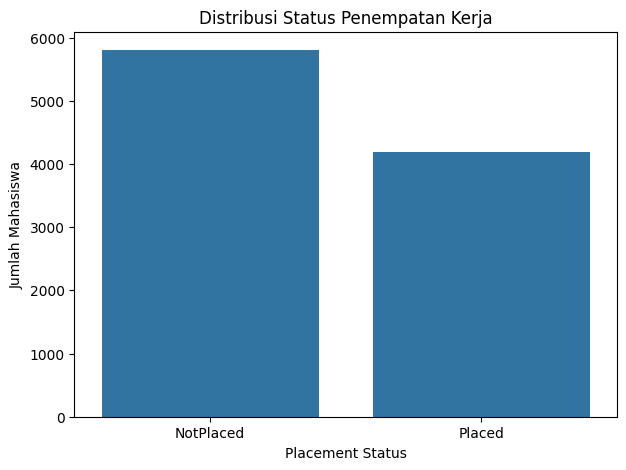

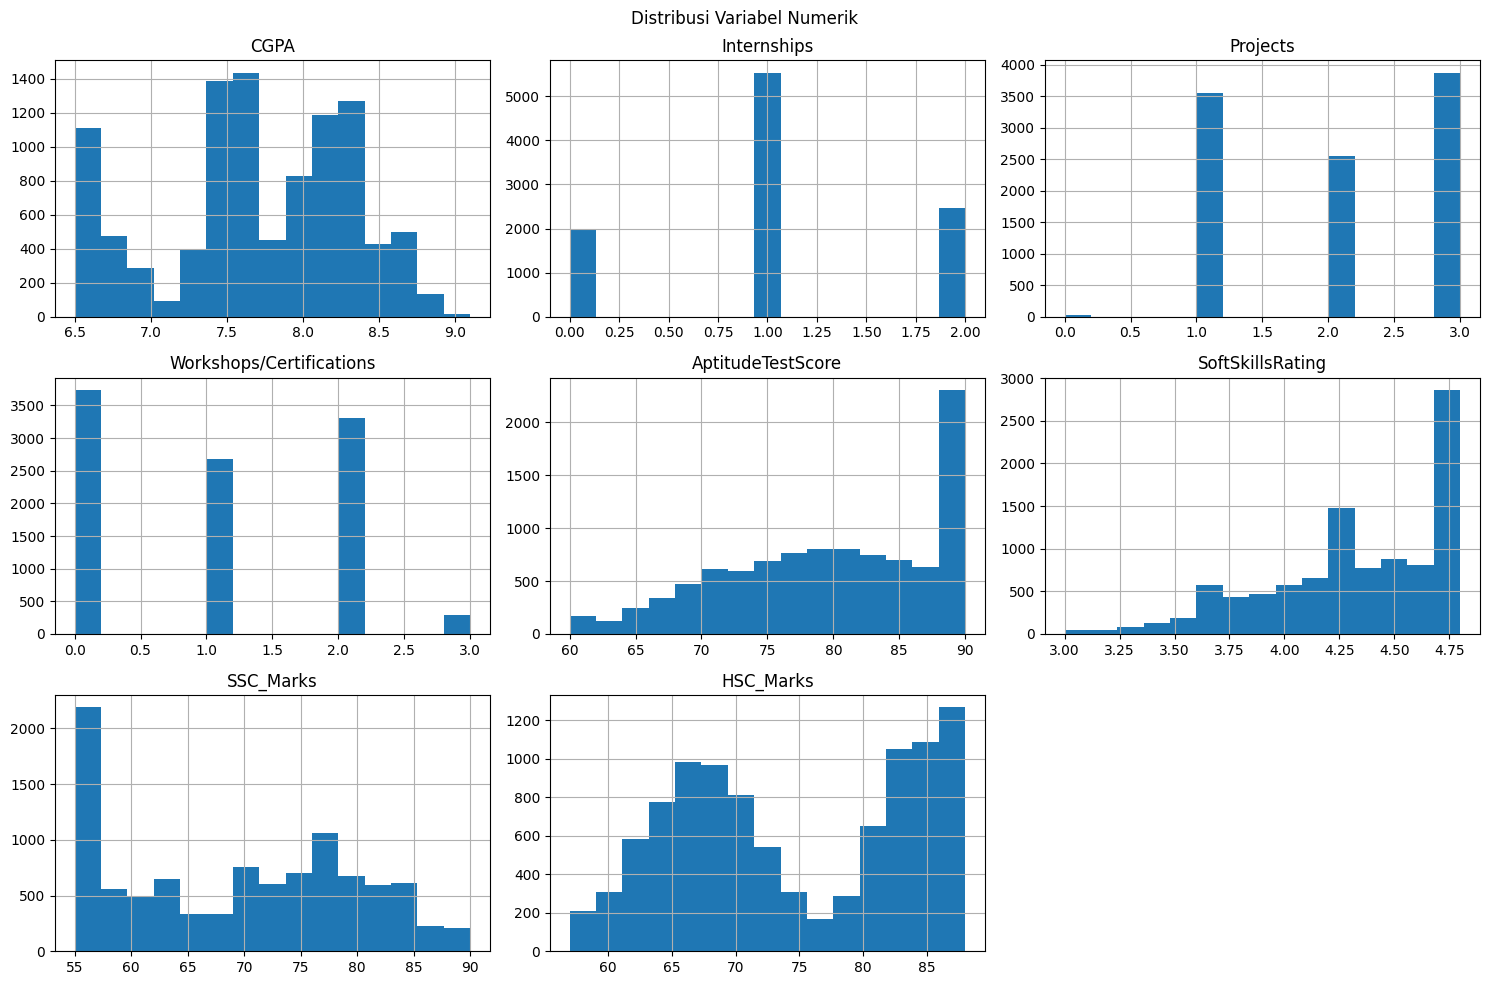

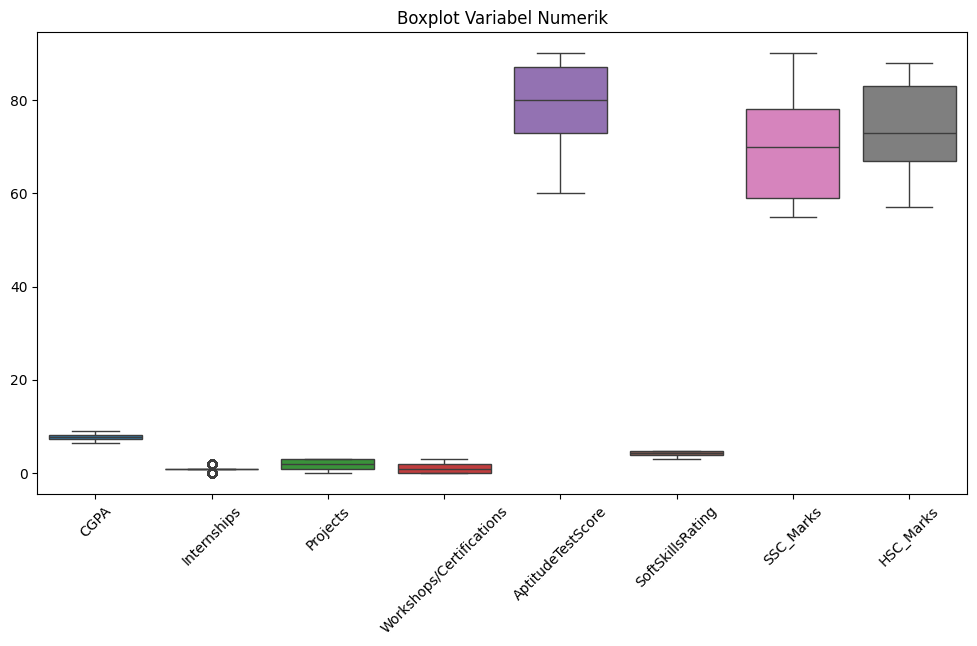

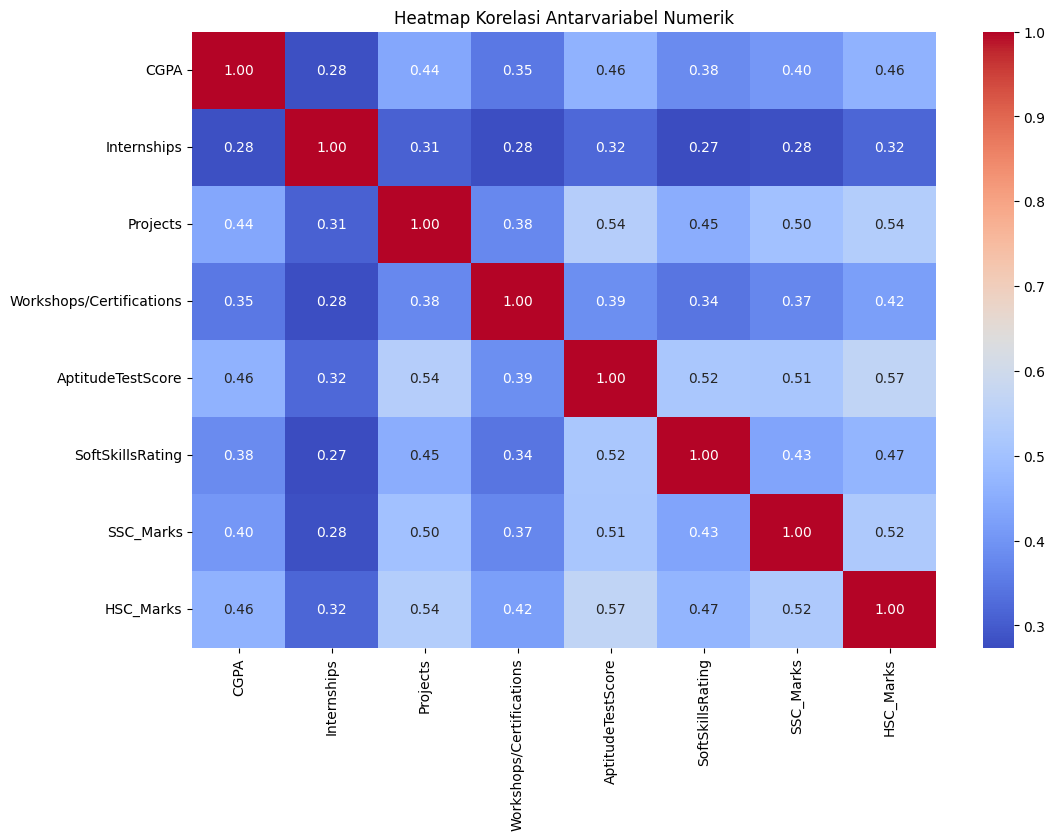

In [37]:
#visualisasi distribbusi target
plt.figure(figsize=(7,5))

sns.countplot(data=data, x='PlacementStatus')

plt.title('Distribusi Status Penempatan Kerja')
plt.xlabel('Placement Status')
plt.ylabel('Jumlah Mahasiswa')

plt.show()

#visualisasi distribusi  variabel numerik
data.select_dtypes(include=['int64', 'float64']).drop(
    columns=['StudentID']
).hist(figsize=(15,10), bins=15)

plt.suptitle('Distribusi Variabel Numerik')
plt.tight_layout()
plt.show()

#visualisasi boxplot
plt.figure(figsize=(12,6))

sns.boxplot(data=numerik)

plt.title('Boxplot Variabel Numerik')
plt.xticks(rotation=45)

plt.show()

#visualisasi heatmap korelasi
plt.figure(figsize=(12,8))

sns.heatmap(
    data.select_dtypes(include=['int64', 'float64']).drop(
        columns=['StudentID']
    ).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Heatmap Korelasi Antarvariabel Numerik')

plt.show()

**2. Validasi Data**

In [38]:
#Validasi kualitas data
#Memeriksa missing value
data.isnull().sum()

,0
StudentID,0
CGPA,0
Internships,0
Projects,0
Workshops/Certifications,0
AptitudeTestScore,0
SoftSkillsRating,0
ExtracurricularActivities,0
PlacementTraining,0
SSC_Marks,0


In [39]:
#Memeriksa data duplikat
data.duplicated().sum()

np.int64(0)

In [40]:
#Memeriksa duplikasi ID
data['StudentID'].duplicated().sum()

np.int64(0)

In [41]:
#Memeriksa konsistensi kategori
for kolom in ['ExtracurricularActivities',
              'PlacementTraining',
              'PlacementStatus']:

    print(kolom)
    print(data[kolom].value_counts(dropna=False))
    print()

ExtracurricularActivities
ExtracurricularActivities
Yes    5854
No     4146
Name: count, dtype: int64

PlacementTraining
PlacementTraining
Yes    7318
No     2682
Name: count, dtype: int64

PlacementStatus
PlacementStatus
NotPlaced    5803
Placed       4197
Name: count, dtype: int64



In [42]:
#Memeriksa rentang nilai numerik
data.describe().T[['min', 'max']]

,min,max
StudentID,1.0,10000.0
CGPA,6.5,9.1
Internships,0.0,2.0
Projects,0.0,3.0
Workshops/Certifications,0.0,3.0
AptitudeTestScore,60.0,90.0
SoftSkillsRating,3.0,4.8
SSC_Marks,55.0,90.0
HSC_Marks,57.0,88.0


In [43]:
#Memeriksa indikasi pencilan menggunakan IQR
# 'numerik' already excludes 'StudentID' from the previous step
for kolom in numerik.columns:

    Q1 = data[kolom].quantile(0.25)
    Q3 = data[kolom].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    pencilan = data[
        (data[kolom] < batas_bawah) |
        (data[kolom] > batas_atas)
    ]

    print(kolom, ":", len(pencilan), "indikasi pencilan")

CGPA : 0 indikasi pencilan
Internships : 4458 indikasi pencilan
Projects : 0 indikasi pencilan
Workshops/Certifications : 0 indikasi pencilan
AptitudeTestScore : 0 indikasi pencilan
SoftSkillsRating : 0 indikasi pencilan
SSC_Marks : 0 indikasi pencilan
HSC_Marks : 0 indikasi pencilan


In [44]:
#Pembersihan data
data_clean = data.copy()

# Menghapus data duplikat
data_clean = data_clean.drop_duplicates()

# Memperbaiki tipe data kategorik
kolom_kategorik = [
    'ExtracurricularActivities',
    'PlacementTraining',
    'PlacementStatus'
]

for kolom in kolom_kategorik:
    data_clean[kolom] = data_clean[kolom].astype(str).str.strip()

# Memastikan jumlah data setelah pembersihan
print("Dimensi data awal:", data.shape)
print("Dimensi data setelah pembersihan:", data_clean.shape)

# Memeriksa kembali missing value
print("\nMissing Value:")
print(data_clean.isnull().sum())

# Memeriksa kembali duplikat
print("\nJumlah Duplikat:")
print(data_clean.duplicated().sum())

Dimensi data awal: (10000, 12)
Dimensi data setelah pembersihan: (10000, 12)

Missing Value:
StudentID                    0
CGPA                         0
Internships                  0
Projects                     0
Workshops/Certifications     0
AptitudeTestScore            0
SoftSkillsRating             0
ExtracurricularActivities    0
PlacementTraining            0
SSC_Marks                    0
HSC_Marks                    0
PlacementStatus              0
dtype: int64

Jumlah Duplikat:
0


**3. Penentuan Label Data**

In [45]:
# Menggunakan data hasil pembersihan dari tahap sebelumnya
df = data_clean.copy()

# 1) Pemeriksaan target: tidak ada nilai hilang dan tepat dua kelas
print("Missing value pada target :", df['PlacementStatus'].isnull().sum())
print("Kelas pada target         :", sorted(df['PlacementStatus'].unique()))
assert df['PlacementStatus'].isnull().sum() == 0, "Target memiliki nilai hilang"
assert df['PlacementStatus'].nunique() == 2, "Target harus memiliki tepat dua kelas"

# 2) Pengkodean label: Placed = 1 (kelas positif), NotPlaced = 0 (kelas negatif)
pemetaan_label = {'NotPlaced': 0, 'Placed': 1}
assert set(df['PlacementStatus'].unique()) == set(pemetaan_label.keys()), \
    "Ada nilai target di luar Placed/NotPlaced (cek penulisan kategori)"

y = df['PlacementStatus'].map(pemetaan_label)

# 3) Pemeriksaan konsistensi hasil pengkodean
print("\nDistribusi label (jumlah):")
print(y.value_counts().sort_index())
print("\nDistribusi label (persen):")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))
print("\nMissing value setelah pengkodean:", y.isnull().sum())

Missing value pada target : 0
Kelas pada target         : ['NotPlaced', 'Placed']

Distribusi label (jumlah):
PlacementStatus
0    5803
1    4197
Name: count, dtype: int64

Distribusi label (persen):
PlacementStatus
0    58.03
1    41.97
Name: proportion, dtype: float64

Missing value setelah pengkodean: 0


**4. Penentuan Objek Data**

In [46]:
# Daftar fitur yang digunakan
fitur_numerik = ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications',
                 'AptitudeTestScore', 'SoftSkillsRating', 'SSC_Marks', 'HSC_Marks']
fitur_kategorik = ['ExtracurricularActivities', 'PlacementTraining']

# Variabel yang dikeluarkan
kolom_dikeluarkan = ['StudentID', 'PlacementStatus']

# Validasi: semua kolom ada, target tidak menjadi fitur, kolom identitas dikeluarkan
semua_fitur = fitur_numerik + fitur_kategorik
assert all(k in df.columns for k in semua_fitur), "Ada fitur yang tidak ditemukan di dataset"
assert 'PlacementStatus' not in semua_fitur, "Target tidak boleh menjadi fitur"
assert 'StudentID' not in semua_fitur, "Kolom identitas tidak boleh menjadi fitur"

# Pastikan tidak ada kolom lain yang terlewat
sisa = set(df.columns) - set(semua_fitur) - set(kolom_dikeluarkan)
print("Kolom yang belum diklasifikasikan:", sisa if sisa else "tidak ada")

print("\nJumlah fitur numerik   :", len(fitur_numerik))
print("Jumlah fitur kategorik :", len(fitur_kategorik))
print("Total fitur            :", len(semua_fitur))

Kolom yang belum diklasifikasikan: tidak ada

Jumlah fitur numerik   : 8
Jumlah fitur kategorik : 2
Total fitur            : 10


In [47]:
# Pemeriksaan awal indikasi data leakage:
# fitur dengan korelasi sangat tinggi terhadap target patut dicurigai
cek = df[fitur_numerik].copy()
for k in fitur_kategorik:
    cek[k] = (df[k] == 'Yes').astype(int)

korelasi_target = cek.corrwith(y).sort_values(ascending=False)
print(korelasi_target.round(3))

mencurigakan = korelasi_target[korelasi_target.abs() > 0.9]
print("\nFitur dengan |korelasi| > 0.9 terhadap target:",
      mencurigakan.index.tolist() if len(mencurigakan) else "tidak ada")

AptitudeTestScore            0.522
HSC_Marks                    0.506
ExtracurricularActivities    0.482
Projects                     0.475
SSC_Marks                    0.470
SoftSkillsRating             0.427
CGPA                         0.423
Workshops/Certifications     0.362
PlacementTraining            0.324
Internships                  0.260
dtype: float64

Fitur dengan |korelasi| > 0.9 terhadap target: tidak ada


**5. Konstruksi Data**

In [48]:
# 1) Pembentukan fitur baru
df['TotalExperience'] = df['Internships'] + df['Projects'] + df['Workshops/Certifications']
fitur_numerik_final = fitur_numerik + ['TotalExperience']

X = df[fitur_numerik_final + fitur_kategorik]
print("Dimensi X:", X.shape, "| Dimensi y:", y.shape)
X.head()

Dimensi X: (10000, 11) | Dimensi y: (10000,)


,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,SSC_Marks,HSC_Marks,TotalExperience,ExtracurricularActivities,PlacementTraining
0,7.5,1,1,1,65,4.4,61,79,3,No,No
1,8.9,0,3,2,90,4.0,78,82,5,Yes,Yes
2,7.3,1,2,2,82,4.8,79,80,5,Yes,No
3,7.5,1,1,2,85,4.4,81,80,4,Yes,Yes
4,8.3,1,2,2,86,4.5,74,88,5,Yes,Yes


In [49]:
from sklearn.model_selection import train_test_split

# 2) Pembagian data latih dan uji 80:20 (stratified, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

# Pemeriksaan proporsi kelas (harus mirip pada data awal, latih, dan uji)
proporsi = pd.DataFrame({
    'Data awal (%)': y.value_counts(normalize=True).sort_index() * 100,
    'Data latih (%)': y_train.value_counts(normalize=True).sort_index() * 100,
    'Data uji (%)': y_test.value_counts(normalize=True).sort_index() * 100
}).round(2)
proporsi.index = ['NotPlaced (0)', 'Placed (1)']
proporsi

X_train: (8000, 11) | X_test: (2000, 11)
y_train: (8000,) | y_test: (2000,)


,Data awal (%),Data latih (%),Data uji (%)
NotPlaced (0),58.03,58.03,58.05
Placed (1),41.97,41.98,41.95


In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 3) Transformasi: imputasi + scaling (numerik) dan imputasi + encoding (kategorik)
pipeline_numerik = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

pipeline_kategorik = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', pipeline_numerik, fitur_numerik_final),
    ('cat', pipeline_kategorik, fitur_kategorik)
], verbose_feature_names_out=False)
preprocessor.set_output(transform='pandas')

# 4) fit hanya pada data latih, lalu terapkan ke data uji
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print("Dimensi X_train_prep:", X_train_prep.shape)
print("Dimensi X_test_prep :", X_test_prep.shape)
print("Kolom hasil transformasi:", X_train_prep.columns.tolist())
X_train_prep.head()

Dimensi X_train_prep: (8000, 11)
Dimensi X_test_prep : (2000, 11)
Kolom hasil transformasi: ['CGPA', 'Internships', 'Projects', 'Workshops/Certifications', 'AptitudeTestScore', 'SoftSkillsRating', 'SSC_Marks', 'HSC_Marks', 'TotalExperience', 'ExtracurricularActivities_Yes', 'PlacementTraining_Yes']


,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,SSC_Marks,HSC_Marks,TotalExperience,ExtracurricularActivities_Yes,PlacementTraining_Yes
8944,-1.560889,-0.078011,-1.184512,-1.114424,-0.539061,-1.523764,-1.074932,-0.950077,-1.147354,0.0,0.0
5241,1.095478,-0.078011,1.125323,-1.114424,1.298491,0.667257,0.846927,1.403853,-0.047500,1.0,1.0
5725,-1.092119,-0.078011,-0.029595,-1.114424,-1.274083,0.910704,-1.171025,-1.062169,-0.597427,0.0,1.0
979,-1.717146,-0.078011,-0.029595,-1.114424,1.053484,-0.793424,0.846927,-0.837985,-0.597427,0.0,0.0
8273,-1.560889,-0.078011,-1.184512,-1.114424,-0.661565,-2.010658,-0.402281,-1.398445,-1.147354,0.0,0.0


In [51]:
# Verifikasi hasil scaling: parameter dipelajari dari data latih saja
print("Data LATIH setelah scaling (rata-rata harus ~0, std ~1):")
print(X_train_prep[fitur_numerik_final].agg(['mean', 'std']).round(3))

print("\nData UJI setelah scaling (tidak harus tepat 0 dan 1, karena memakai parameter data latih):")
print(X_test_prep[fitur_numerik_final].agg(['mean', 'std']).round(3))

print("\nMissing value X_train_prep:", int(X_train_prep.isnull().sum().sum()))
print("Missing value X_test_prep :", int(X_test_prep.isnull().sum().sum()))

Data LATIH setelah scaling (rata-rata harus ~0, std ~1):
      CGPA  Internships  Projects  Workshops/Certifications  \
mean  -0.0          0.0       0.0                      -0.0   
std    1.0          1.0       1.0                       1.0   

      AptitudeTestScore  SoftSkillsRating  SSC_Marks  HSC_Marks  \
mean                0.0               0.0        0.0       -0.0   
std                 1.0               1.0        1.0        1.0   

      TotalExperience  
mean             -0.0  
std               1.0  

Data UJI setelah scaling (tidak harus tepat 0 dan 1, karena memakai parameter data latih):
       CGPA  Internships  Projects  Workshops/Certifications  \
mean -0.007       -0.020     0.006                     0.024   
std   1.001        1.007     1.012                     0.994   

      AptitudeTestScore  SoftSkillsRating  SSC_Marks  HSC_Marks  \
mean              0.030            -0.024     -0.013      0.014   
std               0.998             1.010      1.011      0.

In [52]:
# Menyimpan data hasil split dan transformasi agar identik dipakai kedua model
# (X_train_prep, X_test_prep, y_train, y_test dipakai oleh Anggota 3 dan 4)
os.makedirs('split_data', exist_ok=True)
X_train_prep.to_csv('split_data/X_train_prep.csv', index=False)
X_test_prep.to_csv('split_data/X_test_prep.csv', index=False)
y_train.to_csv('split_data/y_train.csv', index=False)
y_test.to_csv('split_data/y_test.csv', index=False)
print("Data split tersimpan di folder split_data/")

Data split tersimpan di folder split_data/


**6. Pemodelan Algoritma 1: Random Forest**

In [53]:
from sklearn.ensemble import RandomForestClassifier

# Membangun dan melatih model Random Forest
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
model_rf.fit(X_train_prep, y_train)

# Prediksi pada data latih dan data uji (disimpan untuk tahap evaluasi oleh Anggota 4)
y_pred_train_model1 = model_rf.predict(X_train_prep)
y_pred_model1 = model_rf.predict(X_test_prep)
y_proba_model1 = model_rf.predict_proba(X_test_prep)[:, 1]  # probabilitas kelas Placed (1)

print("Model Random Forest berhasil dilatih.")
print("Jumlah pohon :", model_rf.n_estimators)
print("Jumlah fitur :", model_rf.n_features_in_)

Model Random Forest berhasil dilatih.
Jumlah pohon : 100
Jumlah fitur : 11


In [54]:
# Menampilkan hasil prediksi Random Forest pada data uji
label_balik = {0: 'NotPlaced', 1: 'Placed'}

hasil_prediksi = pd.DataFrame({
    'Aktual': y_test.map(label_balik).values,
    'Prediksi': pd.Series(y_pred_model1).map(label_balik).values,
    'Probabilitas Placed': y_proba_model1.round(3)
}, index=y_test.index)

print("10 prediksi pertama pada data uji:")
display(hasil_prediksi.head(10))

print("\nDistribusi hasil prediksi pada data uji:")
print(hasil_prediksi['Prediksi'].value_counts())

10 prediksi pertama pada data uji:


,Aktual,Prediksi,Probabilitas Placed
669,Placed,NotPlaced,0.08
3690,NotPlaced,NotPlaced,0.08
8654,Placed,Placed,0.96
8165,NotPlaced,NotPlaced,0.13
5023,NotPlaced,NotPlaced,0.39
7366,Placed,Placed,0.75
5962,NotPlaced,NotPlaced,0.03
9464,Placed,Placed,0.68
7579,NotPlaced,NotPlaced,0.50
4848,Placed,Placed,0.51



Distribusi hasil prediksi pada data uji:
Prediksi
NotPlaced    1196
Placed        804
Name: count, dtype: int64


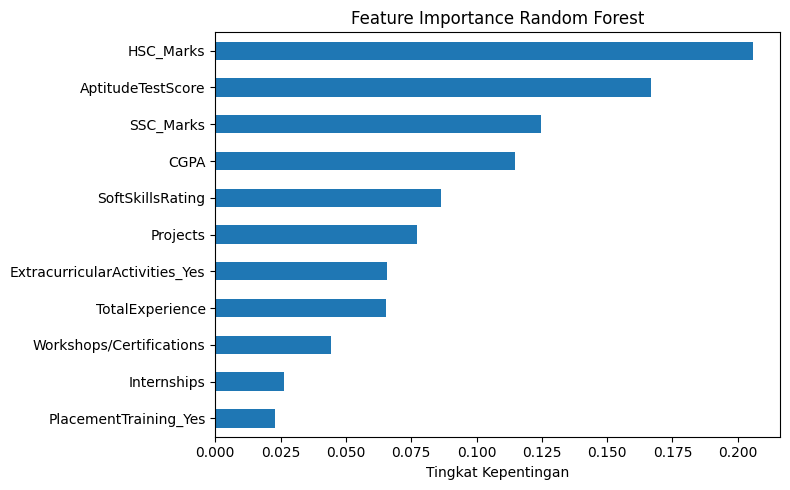

,0
HSC_Marks,0.2058
AptitudeTestScore,0.1666
SSC_Marks,0.1248
CGPA,0.1146
SoftSkillsRating,0.0864
Projects,0.0773
ExtracurricularActivities_Yes,0.0657
TotalExperience,0.0655
Workshops/Certifications,0.0442
Internships,0.0262


In [55]:
# Feature importance Random Forest
importance = pd.Series(model_rf.feature_importances_, index=X_train_prep.columns).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind='barh')
plt.title('Feature Importance Random Forest')
plt.xlabel('Tingkat Kepentingan')
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(4)